# Week 5: Deep Learning Application in Data Science
## Handwritten Digit Classification with PyTorch

**Problem:** classify 8×8 grayscale images of handwritten digits into one of ten classes (0–9).  
**Dataset:** scikit-learn Digits dataset, a publicly available educational dataset (1,797 samples).  
**Framework:** PyTorch.

This is an educational image-classification project. The dataset is small and low-resolution, so results should not be assumed to generalize to real-world handwriting images.

In [35]:
from pathlib import Path
import json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Outputs:", OUTPUT_DIR.resolve())

Device: cpu
Outputs: C:\Users\Tharun\Internship\Week 5 Task Deep Learning Application in Data Science\outputs


## 1. Load and inspect the dataset

Each example is an 8×8 image represented by 64 pixel intensity values. Pixel values range from 0 to 16 and are scaled to [0, 1]. The target is one of ten digits. This task is multiclass classification.

Samples: 1797 | Features: 64 | Classes: [0 1 2 3 4 5 6 7 8 9]
Class counts: {0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}


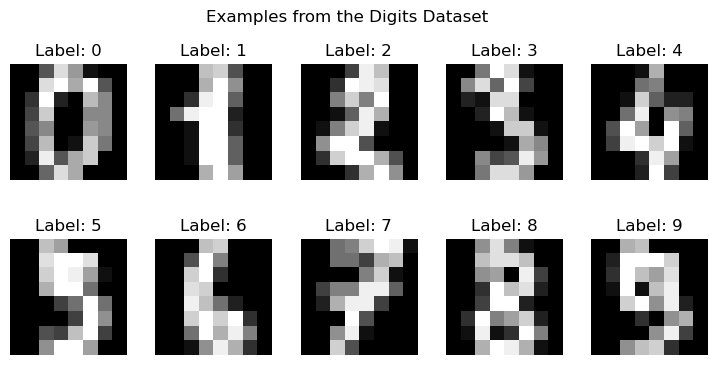

In [45]:
digits = load_digits()
X = digits.data.astype(np.float32) / 16.0
y = digits.target.astype(np.int64)
print("Samples:", len(y), "| Features:", X.shape[1], "| Classes:", np.unique(y))
print("Class counts:", pd.Series(y).value_counts().sort_index().to_dict())

fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for ax, digit in zip(axes.flat, range(10)):
    idx = np.where(y == digit)[0][0]
    ax.imshow(digits.images[idx], cmap="gray")
    ax.set_title(f"Label: {digit}"); ax.axis("off")
fig.suptitle("Examples from the Digits Dataset", y=0.98)
fig.subplots_adjust(hspace=0.45, wspace=0.25, top=0.85)
plt.savefig(FIGURE_DIR / "01_dataset_examples.png", dpi=180); plt.show()

pd.DataFrame({"pixel_"+str(i): X[:, i] for i in range(X.shape[1])}).assign(label=y).to_csv(
    OUTPUT_DIR / "digits_dataset.csv", index=False
)

## 2. Train, validation, and test split

First, reserve 20% of the data as a held-out test set using stratification. Then split 15% of the remaining training portion for validation. The validation set is used for early stopping; the test set is used only for final evaluation. A fixed random seed makes the split reproducible.

In [46]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.15, random_state=SEED, stratify=y_train_full
)
print("Train:", len(y_train), "Validation:", len(y_val), "Test:", len(y_test))

train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(y_train, dtype=torch.long))
loader = DataLoader(train_ds, batch_size=64, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED))
X_val_t = torch.tensor(X_val, device=device); y_val_t = torch.tensor(y_val, dtype=torch.long, device=device)
X_test_t = torch.tensor(X_test, device=device); y_test_t = torch.tensor(y_test, dtype=torch.long, device=device)

Train: 1221 Validation: 216 Test: 360


## 3. Neural-network architecture

The multilayer perceptron (MLP) has 64 input values, two hidden layers (128 and 64 neurons), ReLU activations, dropout regularization, and 10 output logits. Cross-entropy loss is appropriate for multiclass classification with integer class labels. Adam is selected for practical adaptive optimization.

**Architecture:** `64 → Linear(128) → ReLU → Dropout(0.20) → Linear(64) → ReLU → Dropout(0.15) → Linear(10)`.

Dropout randomly disables a fraction of hidden activations during training, which can reduce overfitting. Weight decay adds L2-style regularization to the optimizer.

In [47]:
class DigitMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Dropout(p=0.20),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(p=0.15),
            nn.Linear(64, 10)
        )
    def forward(self, x):
        return self.network(x)

model = DigitMLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.001)
print(model)

DigitMLP(
  (network): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.15, inplace=False)
    (6): Linear(in_features=64, out_features=10, bias=True)
  )
)


## 4. Train with validation monitoring and early stopping

Train for at most 60 epochs using mini-batches of 64. After each epoch, calculate validation loss and accuracy. Save the model state with the lowest validation loss and stop if validation loss fails to improve for eight consecutive epochs. This limits unnecessary training, although early stopping cannot guarantee the absence of overfitting.

Epochs completed: 60 Best validation loss: 0.0655


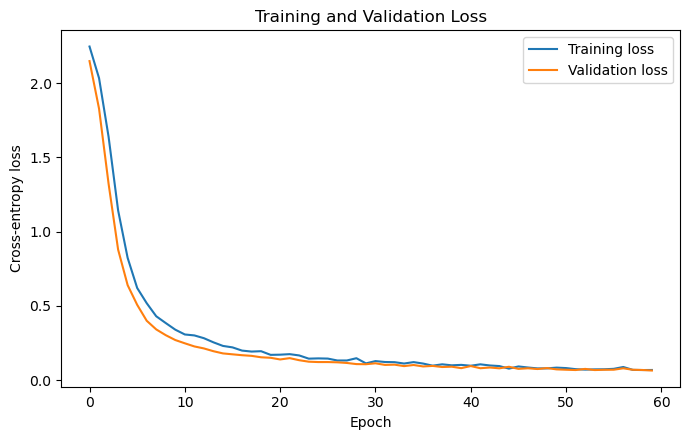

In [48]:
MAX_EPOCHS = 60
PATIENCE = 8
history = {"train_loss": [], "val_loss": [], "val_accuracy": []}
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

for epoch in range(MAX_EPOCHS):
    model.train()
    total_loss = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    train_loss = total_loss / len(train_ds)

    model.eval()
    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = criterion(val_logits, y_val_t).item()
        val_accuracy = (val_logits.argmax(dim=1) == y_val_t).float().mean().item()
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
    if epochs_without_improvement >= PATIENCE:
        print("Early stopping at epoch", epoch + 1)
        break

model.load_state_dict(best_state)
model.to(device)
pd.DataFrame(history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
print("Epochs completed:", len(history["train_loss"]), "Best validation loss:", round(best_val_loss, 4))

plt.figure(figsize=(7, 4.5))
plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.title("Training and Validation Loss")
plt.legend(); plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_training_validation_loss.png", dpi=180); plt.show()

## 5. Test evaluation

After training and selecting the best validation checkpoint, evaluate the model on the held-out test set. Report accuracy and macro-averaged precision, recall, and F1 so each digit class contributes equally to the aggregate metrics. A majority-class baseline is included as a simple reference point.

,test_accuracy,macro_precision,macro_recall,macro_f1,training_majority_baseline_accuracy
0,0.9778,0.9782,0.9776,0.9777,0.1016


              precision    recall  f1-score   support

           0     1.0000    0.9722    0.9859        36
           1     0.9211    0.9722    0.9459        36
           2     1.0000    1.0000    1.0000        35
           3     1.0000    0.9730    0.9863        37
           4     0.9730    1.0000    0.9863        36
           5     0.9737    1.0000    0.9867        37
           6     1.0000    0.9722    0.9859        36
           7     0.9730    1.0000    0.9863        36
           8     0.9412    0.9143    0.9275        35
           9     1.0000    0.9722    0.9859        36

    accuracy                         0.9778       360
   macro avg     0.9782    0.9776    0.9777       360
weighted avg     0.9783    0.9778    0.9778       360



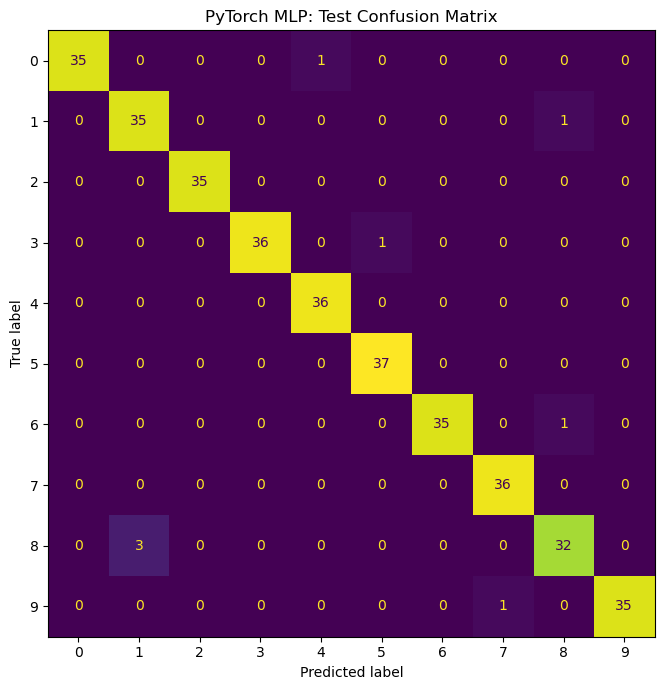

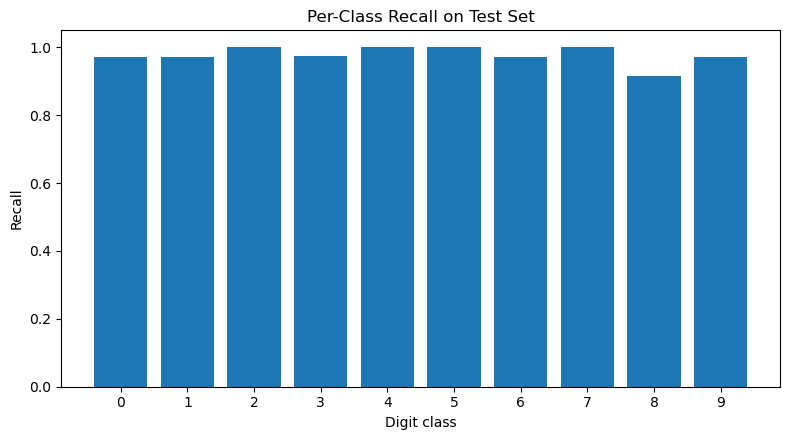

In [49]:
model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    y_pred = test_logits.argmax(dim=1).cpu().numpy()

metrics = {
    "test_accuracy": accuracy_score(y_test, y_pred),
    "macro_precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "macro_recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0)
}
majority_accuracy = pd.Series(y_train).value_counts(normalize=True).max()
metrics["training_majority_baseline_accuracy"] = float(majority_accuracy)
display(pd.DataFrame([metrics]).round(4))
print(classification_report(y_test, y_pred, digits=4))
pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).T.to_csv(
    OUTPUT_DIR / "classification_report.csv"
)

cm = confusion_matrix(y_test, y_pred, labels=list(range(10)))
pd.DataFrame(cm, index=[f"true_{i}" for i in range(10)],
             columns=[f"pred_{i}" for i in range(10)]).to_csv(OUTPUT_DIR / "confusion_matrix.csv")
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10))).plot(
    ax=ax, values_format="d", colorbar=False
)
ax.set_title("PyTorch MLP: Test Confusion Matrix")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "04_confusion_matrix.png", dpi=180); plt.show()

per_class_recall = cm.diagonal() / cm.sum(axis=1)
plt.figure(figsize=(8, 4.5))
plt.bar(range(10), per_class_recall)
plt.xticks(range(10)); plt.ylim(0, 1.05)
plt.xlabel("Digit class"); plt.ylabel("Recall"); plt.title("Per-Class Recall on Test Set")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "05_per_class_recall.png", dpi=180); plt.show()

## 6. Inspect errors and save predictions

Misclassified examples can reveal visually similar digits and help identify where a model struggles. These examples should be treated as qualitative diagnostics, not as proof of a particular cause. Save predictions and probabilities for reproducibility.

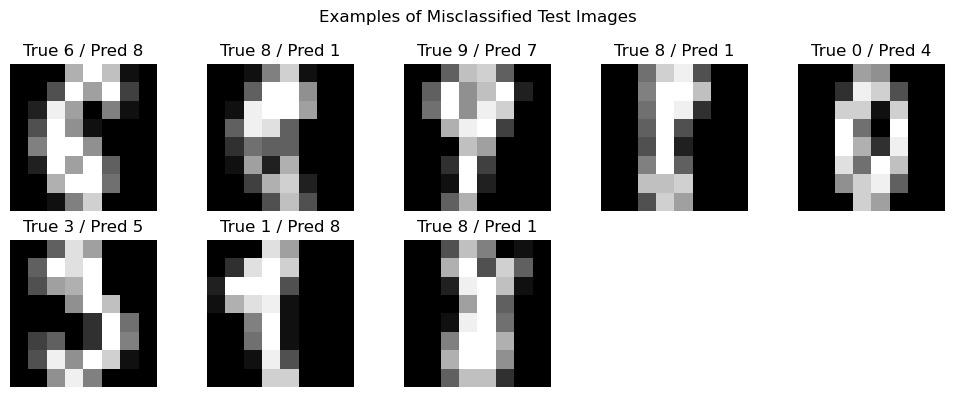

Saved outputs:
outputs/classification_report.csv
outputs/confusion_matrix.csv
outputs/digits_dataset.csv
outputs/experiment_summary.json
outputs/figures/.ipynb_checkpoints/01_dataset_examples-checkpoint.png
outputs/figures/.ipynb_checkpoints/03_training_validation_loss-checkpoint.png
outputs/figures/.ipynb_checkpoints/04_confusion_matrix-checkpoint.png
outputs/figures/.ipynb_checkpoints/05_per_class_recall-checkpoint.png
outputs/figures/.ipynb_checkpoints/06_misclassified_examples-checkpoint.png
outputs/figures/01_dataset_examples.png
outputs/figures/03_training_validation_loss.png
outputs/figures/04_confusion_matrix.png
outputs/figures/05_per_class_recall.png
outputs/figures/06_misclassified_examples.png
outputs/test_metrics.csv
outputs/test_predictions.csv
outputs/training_history.csv


In [50]:
probabilities = torch.softmax(test_logits, dim=1).cpu().numpy()
prediction_table = pd.DataFrame({
    "true_label": y_test,
    "predicted_label": y_pred,
    "confidence_of_predicted_class": probabilities.max(axis=1)
})
prediction_table.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

wrong = np.where(y_pred != y_test)[0][:10]
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.flat, wrong):
    ax.imshow(X_test[idx].reshape(8, 8) * 16, cmap="gray")
    ax.set_title(f"True {y_test[idx]} / Pred {y_pred[idx]}")
    ax.axis("off")
for ax in axes.flat[len(wrong):]:
    ax.axis("off")
fig.suptitle("Examples of Misclassified Test Images")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "06_misclassified_examples.png", dpi=180); plt.show()

summary = {
    "dataset": "scikit-learn Digits",
    "samples": int(len(y)),
    "input_features": int(X.shape[1]),
    "classes": 10,
    "split": {"train": int(len(y_train)), "validation": int(len(y_val)), "test": int(len(y_test)), "random_state": SEED},
    "architecture": "64 -> 128 ReLU Dropout(0.20) -> 64 ReLU Dropout(0.15) -> 10 logits",
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "weight_decay": 0.001,
    "batch_size": 64,
    "epochs_completed": len(history["train_loss"]),
    "best_validation_loss": float(best_val_loss),
    "metrics": {k: float(v) for k, v in metrics.items()}
}
(OUTPUT_DIR / "experiment_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved outputs:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(path.as_posix())